**RESEARCH QUESTION**

**1. Can the world be meaningfully divided into only two clusters (developed vs. developing)?**

Not entirely. Although dividing countries into developed and developing categories can provide a general overview of global inequalities, it oversimplifies the differences between countries. Our dataset shows that countries vary across several indicators, including GDP per capita, life expectancy, education, infant mortality and economic activity.

**2. How many clusters are actually suggested by the data according to the Elbow Rule?**

According to the Elbow Rule, the optimal number of clusters is 2. In our analysis, the most significant change in the curve occurs at K = 2, suggesting that dividing the 207 countries into two clusters provides the most appropriate balance between simplicity and grouping accuracy.

**3. How much of the data structure is explained by two clusters compared to the optimal number of clusters?**

Since the Elbow Rule identifies two as the optimal number of clusters, using two clusters captures the structure identified as optimal by our analysis. Increasing the number of clusters may provide more detailed distinctions between countries, but it also increases complexity.

**4. Does the evidence support the claim in Factfulness that the world cannot be divided into only two groups but into 4?**

Our results provide mixed evidence regarding the claim made in Factfulness. While the Elbow Rule suggests that two clusters are statistically optimal for our dataset, this does not necessarily mean that two groups adequately represent all differences in global development. In fact, our initial three-cluster analysis identified more differentiated groups of countries, suggesting that development exists along a spectrum rather than in two clearly separated categories. Therefore, although our analysis does not statistically confirm that four clusters are optimal, it supports the broader argument in Factfulness that global development is more complex than a simple developed-versus-developing division.

In [2]:
import pandas as pd
df = pd.read_csv('/content/UN.csv')
df

,country,region,tfr,contraception,educationMale,educationFemale,lifeMale,lifeFemale,infantMortality,GDPperCapita,economicActivityMale,economicActivityFemale,illiteracyMale,illiteracyFemale
0,Afghanistan,Asia,6.90,NaN,NaN,NaN,45.0,46.0,154.0,2848.0,87.5,7.2,52.800,85.000
1,Albania,Europe,2.60,NaN,NaN,NaN,68.0,74.0,32.0,863.0,NaN,NaN,NaN,NaN
2,Algeria,Africa,3.81,52.0,11.1,9.9,67.5,70.3,44.0,1531.0,76.4,7.8,26.100,51.000
3,American.Samoa,Asia,NaN,NaN,NaN,NaN,68.0,73.0,11.0,NaN,58.8,42.4,0.264,0.360
4,Andorra,Europe,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
202,Western.Sahara,Africa,3.98,NaN,NaN,NaN,59.8,63.1,64.0,NaN,NaN,NaN,NaN,NaN
203,Yemen,Asia,7.60,7.0,NaN,NaN,57.4,58.4,80.0,732.0,80.6,1.9,32.406,69.552
204,Yugoslavia,Europe,1.80,NaN,NaN,NaN,69.8,75.3,19.0,1487.0,NaN,NaN,1.782,9.072
205,Zambia,Africa,5.49,25.0,7.9,6.8,42.2,43.7,103.0,382.0,NaN,NaN,14.400,28.700


In [4]:
# Inspect the columns, data types, and missing values
print("--- Dataset Information ---")
df.info()

# Identify and summarize only the numeric variables
print("\n--- Descriptive Statistics for Numeric Indicators ---")
dumeric_cols = df.select_dtypes(include=['float64', 'int64'])
display(dumeric_cols.describe())

--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 207 entries, 0 to 206
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   country                 207 non-null    object 
 1   region                  207 non-null    object 
 2   tfr                     197 non-null    float64
 3   contraception           144 non-null    float64
 4   educationMale           76 non-null     float64
 5   educationFemale         76 non-null     float64
 6   lifeMale                196 non-null    float64
 7   lifeFemale              196 non-null    float64
 8   infantMortality         201 non-null    float64
 9   GDPperCapita            197 non-null    float64
 10  economicActivityMale    165 non-null    float64
 11  economicActivityFemale  165 non-null    float64
 12  illiteracyMale          160 non-null    float64
 13  illiteracyFemale        160 non-null    float64
dtypes: float64(12)

,tfr,contraception,educationMale,educationFemale,lifeMale,lifeFemale,infantMortality,GDPperCapita,economicActivityMale,economicActivityFemale,illiteracyMale,illiteracyFemale
count,197.000000,144.000000,76.000000,76.000000,196.00000,196.000000,201.000000,197.000000,165.000000,165.000000,160.000000,160.000000
mean,3.528782,43.430556,11.410526,11.275000,63.62551,68.391837,43.477612,6261.954315,76.460606,46.794545,17.554662,27.906200
std,1.761974,23.706732,3.049834,3.475135,9.78687,11.041234,38.756041,9355.659390,7.687047,16.810472,17.813000,26.580664
min,1.190000,2.000000,3.300000,2.000000,36.00000,39.100000,2.000000,36.000000,51.200000,1.900000,0.200000,0.200000
25%,1.950000,21.000000,9.750000,9.325000,57.37500,59.600000,12.000000,442.000000,72.300000,37.000000,2.952000,4.847000
50%,3.070000,47.000000,11.250000,11.650000,66.50000,72.150000,30.000000,1779.000000,76.800000,48.400000,10.829000,20.100000
75%,4.980000,64.000000,13.900000,13.650000,70.90000,76.425000,66.000000,7272.000000,81.200000,56.400000,27.575000,48.025000
max,8.000000,86.000000,17.200000,17.800000,77.40000,82.900000,169.000000,42416.000000,93.000000,90.600000,79.100000,93.400000


In [5]:
# Identify numeric columns
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns

# Fill missing values with the median of each column
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

# Verify that there are no more missing values
print("Missing values per column after median imputation:")
print(df.isnull().sum())

Missing values per column after median imputation:
country                   0
region                    0
tfr                       0
contraception             0
educationMale             0
educationFemale           0
lifeMale                  0
lifeFemale                0
infantMortality           0
GDPperCapita              0
economicActivityMale      0
economicActivityFemale    0
illiteracyMale            0
illiteracyFemale          0
dtype: int64


In [7]:
from sklearn.preprocessing import StandardScaler
# Drop the non-numeric columns 'country' and 'region' and scale the numeric features
features = df.drop(['country', 'region'], axis=1)
X_std = StandardScaler().fit_transform(features)
X_std

array([[ 1.97595359,  0.12558412, -0.03207616, ..., -2.66546563,
         2.31799   ,  2.50235813],
       [-0.52792052,  0.12558412, -0.03207616, ...,  0.08544586,
        -0.3276982 , -0.25649128],
       [ 0.17665801,  0.37846266, -0.11371262, ..., -2.62540381,
         0.6349261 ,  1.05704411],
       ...,
       [-0.99375756,  0.12558412, -0.03207616, ...,  0.08544586,
        -0.8979858 , -0.72528314],
       [ 1.1549158 , -0.98708144, -1.85529036, ...,  0.08544586,
        -0.10259628,  0.10908815],
       [ 0.68325579,  0.17615983, -0.03207616, ..., -0.02806263,
        -0.40516956, -0.25649128]], shape=(207, 12))

In [8]:
pd.DataFrame(X_std, columns=features.columns).agg(['mean', 'std']).round(3)

,tfr,contraception,educationMale,educationFemale,lifeMale,lifeFemale,infantMortality,GDPperCapita,economicActivityMale,economicActivityFemale,illiteracyMale,illiteracyFemale
mean,-0.000,-0.000,0.000,-0.000,0.000,-0.000,-0.000,0.000,0.000,0.000,0.000,0.000
std,1.002,1.002,1.002,1.002,1.002,1.002,1.002,1.002,1.002,1.002,1.002,1.002


Explain why scaling is required before clustering?

Scaling prevents the data from being majorly influenced by outliers, skewing the data to unwanted ends. It ensures that each indicator contributes equally to the final cluster

In [9]:
from sklearn.cluster import KMeans

# Initialize and fit the K-means algorithm
kmeans = KMeans(n_clusters=3, random_state=42)
df['cluster'] = kmeans.fit_predict(X_std)

# Show the count of countries in each cluster
print(df['cluster'].value_counts())

# Display some sample countries from each cluster
for cluster_id in sorted(df['cluster'].unique()):
    print(f"\n--- Cluster {cluster_id} Countries ---")
    print(df[df['cluster'] == cluster_id]['country'].head(10).tolist())

cluster
0    111
1     55
2     41
Name: count, dtype: int64

--- Cluster 0 Countries ---
['Albania', 'Algeria', 'American.Samoa', 'Andorra', 'Antigua', 'Argentina', 'Armenia', 'Azerbaijan', 'Bahrain', 'Barbados']

--- Cluster 1 Countries ---
['Afghanistan', 'Angola', 'Bangladesh', 'Benin', 'Bhutan', 'Botswana', 'Burkina.Faso', 'Burundi', 'Cambodia', 'Cameroon']

--- Cluster 2 Countries ---
['Australia', 'Austria', 'Bahamas', 'Belgium', 'Canada', 'Czech.Republic', 'Denmark', 'Finland', 'France', 'French.Guiana']


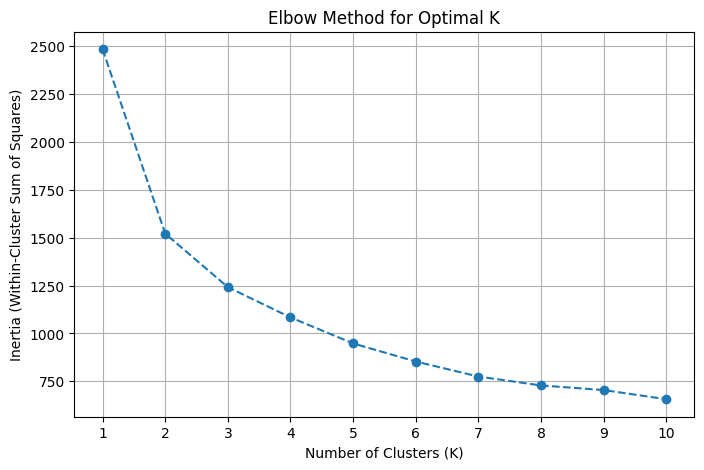

In [10]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Calculate inertia for different values of K
inertia = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_std)
    inertia.append(kmeans.inertia_)

# Plot the elbow curve
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, marker='o', linestyle='--')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.title('Elbow Method for Optimal K')
plt.xticks(k_range)
plt.grid(True)
plt.show()

Recommended number of clusters (K) according to the Elbow Rule: 2


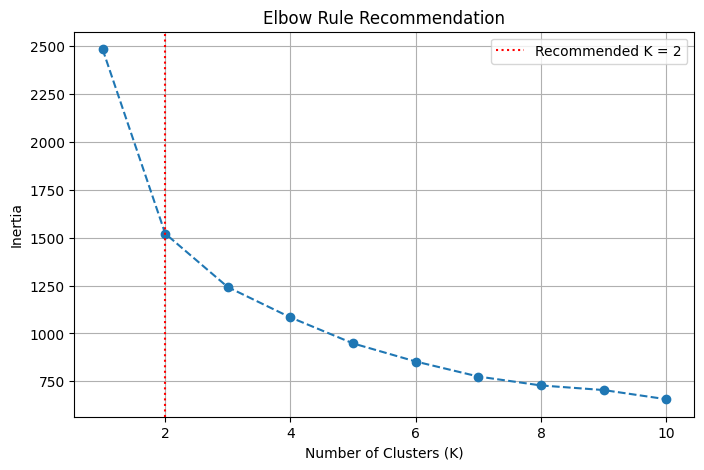

In [11]:
import numpy as np

# Calculate the differences in inertia to find where the change slows down
diffs = np.diff(inertia)
diffs_v2 = np.diff(diffs)

# The elbow is typically where the acceleration of the curve change is maximized
optimal_k = k_range[np.argmax(diffs_v2) + 1]
print(f"Recommended number of clusters (K) according to the Elbow Rule: {optimal_k}")

# Re-plot indicating the recommended K
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, marker='o', linestyle='--')
plt.axvline(x=optimal_k, color='r', linestyle=':', label=f'Recommended K = {optimal_k}')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Rule Recommendation')
plt.legend()
plt.grid(True)
plt.show()

In [12]:
from sklearn.cluster import KMeans

# Since optimal K from the elbow rule is 2, both conditions point to K=2
optimal_k = 2
kmeans_opt = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['cluster_optimal'] = kmeans_opt.fit_predict(X_std)

# Print the cluster sizes
print("Cluster counts for optimal K = 2:")
print(df['cluster_optimal'].value_counts())

# Display sample countries from each of the 2 clusters
for cluster_id in sorted(df['cluster_optimal'].unique()):
    print(f"\n--- Cluster {cluster_id} Countries ---")
    print(df[df['cluster_optimal'] == cluster_id]['country'].head(15).tolist())

Cluster counts for optimal K = 2:
cluster_optimal
0    143
1     64
Name: count, dtype: int64

--- Cluster 0 Countries ---
['Albania', 'Algeria', 'American.Samoa', 'Andorra', 'Antigua', 'Argentina', 'Armenia', 'Australia', 'Austria', 'Azerbaijan', 'Bahamas', 'Bahrain', 'Barbados', 'Belarus', 'Belgium']

--- Cluster 1 Countries ---
['Afghanistan', 'Angola', 'Bangladesh', 'Benin', 'Bhutan', 'Botswana', 'Burkina.Faso', 'Burundi', 'Cambodia', 'Cameroon', 'Central.African.Rep', 'Chad', 'Comoros', 'Congo', 'Dem.Rep.of.the.Congo']


**CONCLUSION**
*Explain whether the analysis supports the idea that the world cannot be divided into only two groups*

Our analysis suggests that the world cannot be fully divided into two groups. Although the Elbow Rule identifies two optimal clusters, the three-cluster analysis initially performed shows that countries can have different combinations of economic, educational and demographic characteristics. This supports the central argument of Factfulness: development is not simply divided into two opposite categories, but exists across different levels and dimensions. However, it is important to recognize that our final clustering solution uses two clusters, based on the statistical results of the Elbow Rule.

**Cluster 0: Albania**
Albania represents a group of countries with generally better demographic and development indicators than those in Cluster 1. For example, Albania has a life expectancy of 68 years for men and 74 years for women, alongside an infant mortality rate of 32 per 1,000 births. These characteristics distinguish this cluster through comparatively higher life expectancy and lower infant mortality.

**Cluster 1: Bangladesh**
 Bangladesh represents a group of countries with more challenging socioeconomic and demographic conditions. It belongs to this cluster because its development indicators are more similar to countries experiencing lower levels of development, particularly in areas such as income, healthcare and living conditions. It shares several characteristics with countries such as Angola, Benin and Cambodia, which are also assigned to this cluster. These characteristics distinguish Cluster 1 from Cluster 0, which generally contains countries with stronger socioeconomic indicators. Interestingly, countries from different continents are grouped together, showing that geographical proximity does not necessarily determine development patterns. Bangladesh therefore provides a recognizable example of why the world cannot be accurately divided into just two simplistic categories.